In [191]:
import numpy as np
import pandas as pd
import torch
import umap
import hdbscan
from collections import defaultdict
import json
import matplotlib.pyplot as plt

In [2]:
PALABRAS_CSV = {  # salida de reconstruir_palabras.py, por modelo
    "mex_state":   "output/words_mex_state.csv",
    "mex_large":   "output/words_mex_large.csv",
    "beto":        "output/words_beto.csv",
    "bertin":      "output/words_bertin.csv",
    "robertuito":  "output/words_robertuito.csv",
}

In [62]:
def get_tweet(palabras_df, id_tweet, special_token=None):

    RED = "\033[91m"
    RESET = "\033[0m" 

   
    l = list(palabras_df[palabras_df['id_tweet']==id_tweet]['word_normalized'])
    l = [str(_) for _ in l]
    
    if special_token==None:
        print(" ".join(l))
        return
    
    s = ""
    for w in l:
        if w==special_token:
            s += RED + w + RESET + " "
        else:
            s += w + " "
    print(s)
    return 

In [619]:
model_name = 'mex_large'

In [646]:
def cargar_embeddings(nombre_modelo, carpeta_salida='embeddings'):
    data = np.load(f"embeddings/{nombre_modelo}_embeddings.npz", allow_pickle=True)
    X, words, id_t = data["embeddings"], data["words"], data['id_tweets']
    return X, words, id_t

data = pd.read_csv(PALABRAS_CSV[model_name])

emb, w, id_tweets = cargar_embeddings(model_name)
emb /= np.linalg.norm(emb, axis=1).reshape(-1, 1)
df = pd.DataFrame(list(w), columns=['palabra'])
df['id_tweet'] = id_tweets
perm = df['id_tweet'].argsort().tolist()
df = df.iloc[perm]
emb = emb[perm]
# agregar la región a las palabras en df
region_por_tweet = data.drop_duplicates("id_tweet").set_index("id_tweet")["region"]
df["region"] = df["id_tweet"].map(region_por_tweet)
df['region_codes'] = pd.Categorical(df['region']).codes

In [621]:
df.head(2)

,palabra,id_tweet,region,region_codes
0,lava,0,Jalisco,12
114,jaja,0,Jalisco,12


In [622]:
#df = df[0:100000]


In [648]:
reducer = umap.UMAP(metric='cosine', n_components=2, n_neighbors=15)
u = reducer.fit_transform(emb)



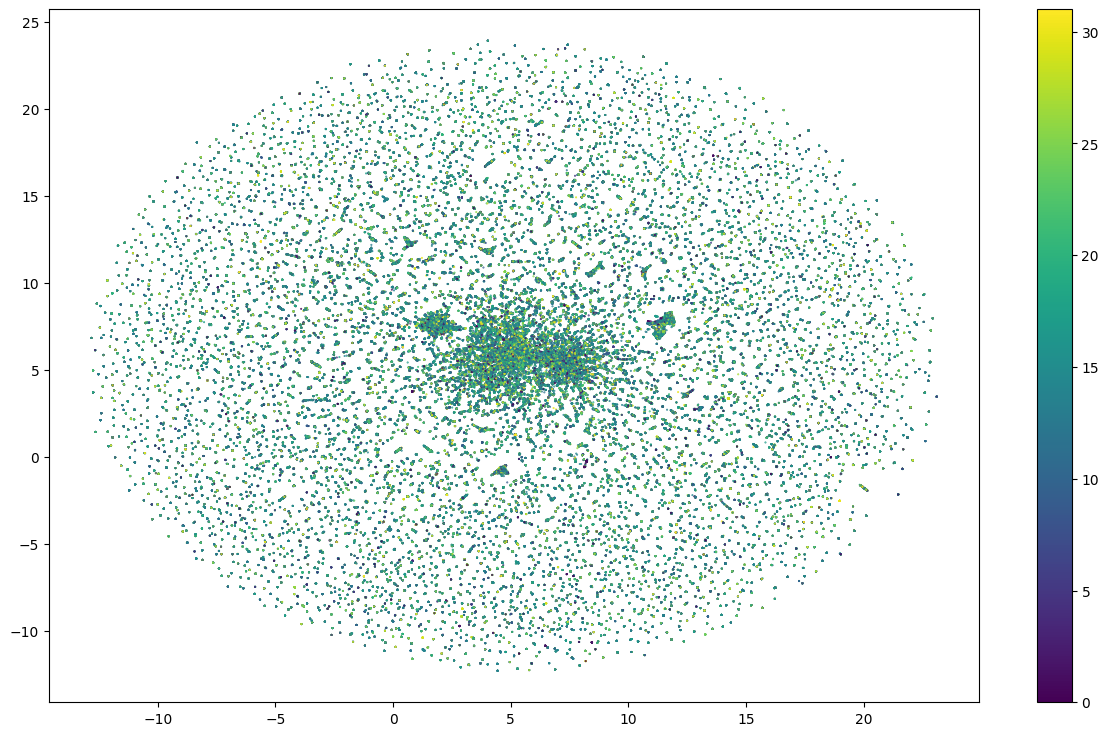

In [649]:
plt.figure(figsize=(15, 9))
scatter = plt.scatter(u[:, 0], u[:, 1], s=.2, c=df['region_codes'])
plt.colorbar(scatter, label="")
plt.show()


In [650]:
from sklearn.cluster import DBSCAN

In [781]:
clr = DBSCAN(eps=.05, min_samples=8)
cluster_labels = clr.fit_predict(u)

In [782]:
df['dbscan_cluster'] = cluster_labels

In [783]:
cluster, count = np.unique(cluster_labels, return_counts=True)
len(cluster)

7570

Ruido: 5875


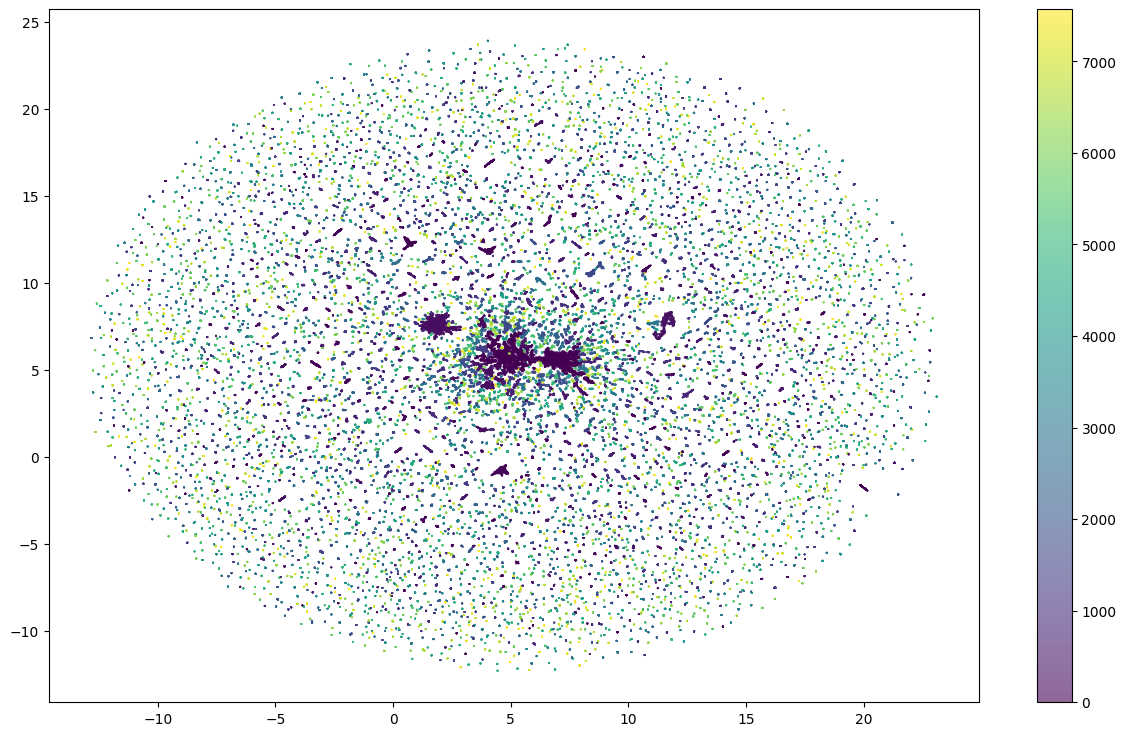

In [784]:
s = u[cluster_labels > -1]
cl = cluster_labels[cluster_labels > -1]
print("Ruido:", len(u) - len(s))
plt.figure(figsize=(15, 9))
scatter = plt.scatter(s[:, 0], s[:, 1], s=.1, c=cl, alpha=0.6, )
plt.colorbar(scatter, label="")
plt.show()

In [785]:
tokens_in_clusters = (df
                      .groupby("palabra")['dbscan_cluster']
                      .unique()
                      .reset_index(name="clusters")
                     )
df2 = df.groupby("palabra")['dbscan_cluster'].nunique().reset_index(name="num_clusters")
tokens_in_clusters['num_clusters'] = df2['num_clusters']
df3 = df.groupby("palabra")['id_tweet'].nunique().reset_index(name="num_tweets")
tokens_in_clusters['num_tweets'] = df3['num_tweets']

In [786]:
tokens_in_clusters.head(2)

,palabra,clusters,num_clusters,num_tweets
0,aaaaah,"[-1, 1042]",2,8
1,aaaah,[1042],1,7


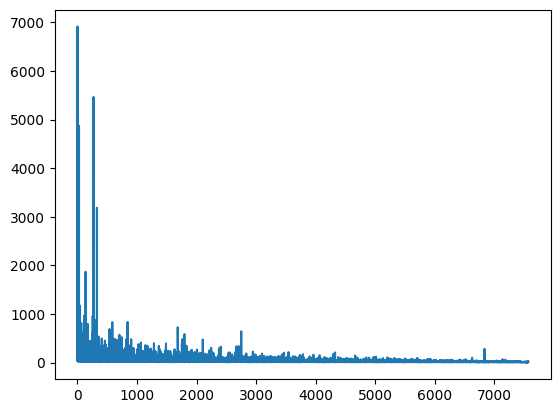

In [787]:
plt.plot(count)
plt.show()

In [806]:
mask = (count < 1000) 
mask[0] = False
decent_clusters = []
num_decent_clusters = []
for i, d in tokens_in_clusters.iterrows():
    c = d['clusters']
    c_ = []
    
    for j in range(len(c)):
        #num_tweets_in_cluster = df[(df['palabra']==d['palabra']) & (df['dbscan_cluster']==c[j])]['id_tweet'].nunique()
        if mask[c[j]+1]: #and (num_tweets_in_cluster>5):
            c_.append(c[j])
    decent_clusters.append(c_)
    num_decent_clusters.append(len(c_))

In [807]:
tokens_in_clusters['decent_clusters'] = decent_clusters
tokens_in_clusters['num_decent_clusters'] = num_decent_clusters

In [808]:
tokens_in_clusters['num_decent_clusters'].unique()

array([ 1,  2,  0,  4,  3,  5,  8,  6,  7, 10,  9])

In [809]:
print(tokens_in_clusters.shape)
tokens_in_clusters.head(2)

(12434, 6)


,palabra,clusters,num_clusters,num_tweets,decent_clusters,num_decent_clusters
0,aaaaah,"[-1, 1042]",2,8,[1042],1
1,aaaah,[1042],1,7,[1042],1


In [810]:
tokens_in_clusters[tokens_in_clusters['palabra'] == 'jugar']

,palabra,clusters,num_clusters,num_tweets,decent_clusters,num_decent_clusters
6571,jugar,"[2597, 250, 270]",3,154,"[2597, 250]",2


In [811]:
same_number_clusters = tokens_in_clusters[tokens_in_clusters['num_decent_clusters'] == 2]
same_number_clusters_tokens = []
for i, d in same_number_clusters.iterrows():
    #if (len(d['palabra']) < 4):
    #    continue
    same_number_clusters_tokens.append(d['palabra'])
best_tokens = []
for token in same_number_clusters['palabra']:
    token_clusters = tokens_in_clusters[tokens_in_clusters['palabra']==token]['decent_clusters']
    token_clusters = token_clusters.to_list()[0] 

    for tk_cl in token_clusters:        
        df_ = df[df['dbscan_cluster'] == tk_cl]
        id_tweets = df_[df_['palabra']==token]['id_tweet'].to_list()
        if (len(id_tweets) < 1):
            break
    else:
        best_tokens.append(token)

In [812]:
"jugar" in best_tokens

True

In [616]:
len(best_tokens), list(enumerate(best_tokens))

(1994,
 [(0, np.str_('abejas')),
  (1, np.str_('abierto')),
  (2, np.str_('abogado')),
  (3, np.str_('abrazar')),
  (4, np.str_('abrazarte')),
  (5, np.str_('abrazos')),
  (6, np.str_('abro')),
  (7, np.str_('absoluta')),
  (8, np.str_('absolutamente')),
  (9, np.str_('absurdo')),
  (10, np.str_('abuela')),
  (11, np.str_('abuelita')),
  (12, np.str_('abuelo')),
  (13, np.str_('abuelos')),
  (14, np.str_('aburrido')),
  (15, np.str_('abusos')),
  (16, np.str_('acaban')),
  (17, np.str_('acabas')),
  (18, np.str_('acaso')),
  (19, np.str_('accesorios')),
  (20, np.str_('acento')),
  (21, np.str_('acerca')),
  (22, np.str_('acordar')),
  (23, np.str_('acorde')),
  (24, np.str_('acoso')),
  (25, np.str_('activa')),
  (26, np.str_('actividades')),
  (27, np.str_('activo')),
  (28, np.str_('acto')),
  (29, np.str_('actos')),
  (30, np.str_('actriz')),
  (31, np.str_('actual')),
  (32, np.str_('actualizaciones')),
  (33, np.str_('admiro')),
  (34, np.str_('adquisitivo')),
  (35, np.str_('adu

In [802]:
def centroide(cluster, X, clusters):
    mask = clusters==cluster
    S = X[mask]
    return np.mean(S, axis=0), mask

def plot_subset(mask, u, size=0.3, color='b'):
    s = u[mask]
    #plt.figure(figsize=(15, 9))
    scatter = plt.scatter(s[:, 0], s[:, 1], s=size, alpha=0.6, color=color)    
    #plt.colorbar(scatter, label="")
    


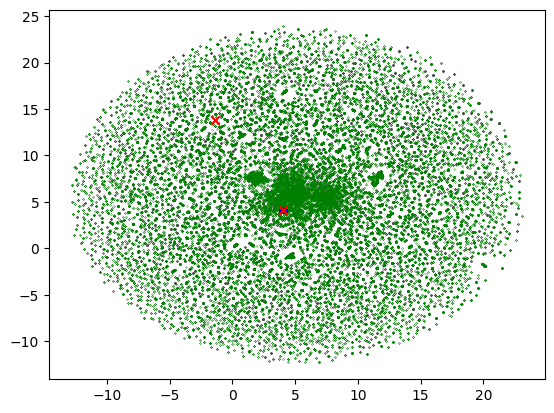

In [814]:
c1, mask1 = centroide(2597, u, df['dbscan_cluster'])
c2, mask2 = centroide(250, u, df['dbscan_cluster'])
#c3, mask3 = centroide(270, u, df['dbscan_cluster'])

plot_subset([True]*len(u), u, size=0.01, color='g')
plot_subset(mask1|mask2, u, color='b')
plt.scatter(c1[0], c1[1], marker='x', c='r')
plt.scatter(c2[0], c2[1], marker='x', c='r')
#plt.scatter(c3[0], c3[1], marker='x', c='r')
plt.show()

In [815]:
#token = best_tokens[138]
token = 'jugar'

token_clusters = tokens_in_clusters[tokens_in_clusters['palabra']==token]['decent_clusters']
token_clusters = token_clusters.to_list()[0] 
print(token)
#print(cluster_dist(token_clusters[0], token_clusters[1], s, cl))
for tk_cl in token_clusters:
    print("_"*50)
    df_ = df[df['dbscan_cluster']==tk_cl]
    print("Cluster:", tk_cl, "len:", len(df_))
    
    id_tweets = df_[df_['palabra']==token]['id_tweet'].to_list()
    print("Total tweets:", len(id_tweets))
    print("Tokens in cluster:", df_['palabra'].unique())
    for id_t in id_tweets[0:5]:
        print()
        get_tweet(data, id_t, special_token=token)

jugar
__________________________________________________
Cluster: 2597 len: 169
Total tweets: 158
Tokens in cluster: [np.str_('jugaron') np.str_('jugar') np.str_('jugaremos')
 np.str_('jugarle')]

nl _geo no fui al gym para jugar a gusto y salí lastimada del partido 

jalisco _geo esto y jugar ruleta rusa supongo es la misma vrg 😳😳😳😳 

mexico_city _geo yo no entiendo porque traer a un toplaner retirado a jugar # worlds2021 pudieron haber pedido prestado a biopanther xd 

coahuila _geo yo opino que si es mejor que obedezca a la convocatoria para que así obtenga más rating y sea en su momento más vendible en el siguiente mercado de transferencias de otra manera sin jugar y a estas alturas ya no es rentable 

sinaloa _geo días hoy por la tarde cinépolis gran plaza alguna # teen # hotwife que quiera jugar en la sala # mazatlan _url 
__________________________________________________
Cluster: 250 len: 432
Total tweets: 5
Tokens in cluster: [np.str_('conjunto') np.str_('advierte') np.s